# Mini-Project 1: Weather forecast

The reusable HTTP, parsing, validation, and retry logic lives in `src/weather.py`. The notebook runs against saved sample responses by default so that **Restart & Run All works offline**. To make live requests, set `USE_LIVE_APIS = True` below and provide your own university email in `WEATHER_CONTACT_EMAIL`; never put personal contact details in shared source.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt

from src.weather import (
    choose_location,
    geocode,
    geocode_with_urllib,
    get_forecast,
    get_met_forecast,
    parse_met_forecast,
    parse_locations,
    parse_forecast,
)

# Configuration: these are the only values to change for another live run.
LOCATION_NAME = "Dresden"
LOCATION_CANDIDATE_INDEX = 0
DAYS = 2
CONTACT_EMAIL = os.getenv("WEATHER_CONTACT_EMAIL", "")
USE_LIVE_APIS = False
FIXTURES = Path("tests/fixtures")

## Part A: HTTP approaches

The first call uses `urllib.request`, `urllib.parse.urlencode`, and `json`; the second uses `requests` with `params=` and a timeout. The shared request helper records the status, content type, and elapsed time, calls `raise_for_status()`, retries connection failures and server errors with capped exponential backoff, and raises a project-specific error after the retry limit. In live mode the candidate list is shown before the configured candidate index is selected.

In [2]:
if USE_LIVE_APIS:
    if not CONTACT_EMAIL.strip():
        raise ValueError("Set WEATHER_CONTACT_EMAIL to your own university email before live API use.")
    urllib_candidates = geocode_with_urllib(LOCATION_NAME)
    request_candidates = geocode(LOCATION_NAME)
    print("urllib candidates:")
    print("\n".join(f"{i}: {place}" for i, place in enumerate(urllib_candidates)))
    print("requests candidates:")
    print("\n".join(f"{i}: {place}" for i, place in enumerate(request_candidates)))
    location = choose_location(request_candidates, LOCATION_CANDIDATE_INDEX)
    forecast, api_response = get_forecast(location.latitude, location.longitude, DAYS)
    met_response = get_met_forecast(location.latitude, location.longitude, CONTACT_EMAIL)
    met_forecast = parse_met_forecast(met_response.payload)
    print(f"Forecast status: {api_response.status_code}")
    print(f"Content-Type: {api_response.content_type}")
    print(f"Response time: {api_response.elapsed_seconds:.3f} seconds")
else:
    with (FIXTURES / "dresden_geocoding.json").open(encoding="utf-8") as file:
        sample_locations = json.load(file)
    with (FIXTURES / "forecast.json").open(encoding="utf-8") as file:
        sample_forecast = json.load(file)
    with (FIXTURES / "met_forecast.json").open(encoding="utf-8") as file:
        sample_met_forecast = json.load(file)
    request_candidates = parse_locations(sample_locations)
    location = choose_location(request_candidates, LOCATION_CANDIDATE_INDEX)
    forecast = parse_forecast(sample_forecast)
    met_forecast = parse_met_forecast(sample_met_forecast)
    api_response = None
    met_response = None
    print("Offline sample mode: status and response-time metadata are not available.")

print(f"Selected location: {location}")

Offline sample mode: status and response-time metadata are not available.
Selected location: Dresden, Saxony, Germany (51.0500, 13.7500)


### Comparing the HTTP clients

`urllib` is in the standard library and makes dependencies explicit, but request construction, response decoding, and HTTP error handling require more code. `urlencode` handles query escaping, and `urlopen` supports explicit timeout control; status and headers are available from its response object. `requests` is shorter for query parameters (`params=`), handles response decoding conveniently, and exposes status and timing metadata directly. Both approaches still need explicit timeouts and error handling. The production helper uses `requests`, calls `raise_for_status()`, and distinguishes retryable network/5xx failures from non-retryable client errors.

**Weather data by [Open-Meteo.com](https://open-meteo.com/)** — API data are licensed under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Sample-mode values are saved sample responses, not a live forecast.

,Date,Maximum temperature (°C),Minimum temperature (°C),Precipitation (mm),Maximum wind speed (km/h),Weather
0,2026-10-24,13.2,5.1,0.0,12.0,Partly cloudy
1,2026-10-25,14.0,6.3,1.4,18.5,Slight rain


2 daily forecast rows for Dresden.
Forecast table uses the saved Open-Meteo-format sample fixture.
MET Norway second-source sample/current forecast:


,Time (UTC),Temperature (°C),Wind speed (m/s),Precipitation (mm),Weather
0,2026-10-24T12:00:00Z,12.4,3.2,0.0,partlycloudy_day


MET Norway data: https://api.met.no/ (CC BY 4.0; changes made for this display).


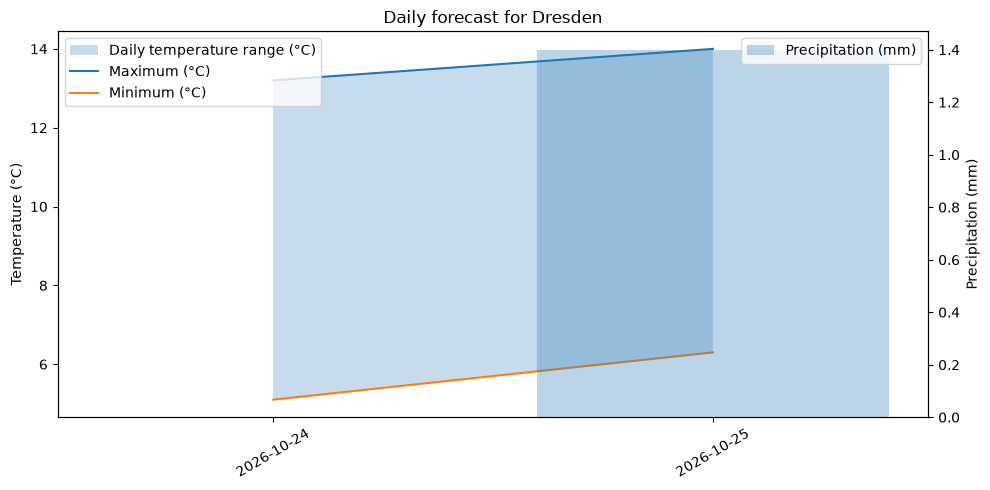

In [3]:
display(forecast)
print(f"{len(forecast)} daily forecast rows for {location.name}.")
if api_response is not None:
    print("Weather data by Open-Meteo.com: https://open-meteo.com/ (CC BY 4.0).")
else:
    print("Forecast table uses the saved Open-Meteo-format sample fixture.")
print("MET Norway second-source sample/current forecast:")
display(met_forecast.head())
print("MET Norway data: https://api.met.no/ (CC BY 4.0; changes made for this display).")

fig, temperature_axis = plt.subplots(figsize=(10, 5))
dates = forecast["Date"]
temperature_axis.fill_between(
    range(len(forecast)),
    forecast["Minimum temperature (°C)"],
    forecast["Maximum temperature (°C)"],
    alpha=0.25,
    label="Daily temperature range (°C)",
)
temperature_axis.plot(range(len(forecast)), forecast["Maximum temperature (°C)"], label="Maximum (°C)")
temperature_axis.plot(range(len(forecast)), forecast["Minimum temperature (°C)"], label="Minimum (°C)")
temperature_axis.set_xticks(range(len(forecast)), dates, rotation=30)
temperature_axis.set_ylabel("Temperature (°C)")
temperature_axis.set_title(f"Daily forecast for {location.name}")
precipitation_axis = temperature_axis.twinx()
precipitation_axis.bar(
    range(len(forecast)),
    forecast["Precipitation (mm)"],
    alpha=0.3,
    color="tab:blue",
    label="Precipitation (mm)",
)
precipitation_axis.set_ylabel("Precipitation (mm)")
temperature_axis.legend(loc="upper left")
precipitation_axis.legend(loc="upper right")
fig.tight_layout()
plt.show()

if met_response is not None:
    print("Second source: MET Norway Locationforecast; attribution and terms apply.")

## Part C: failure handling and test command

Try an unknown city, latitude outside `[-90, 90]`, a mocked connection failure, and a deliberately tiny timeout to observe explicit errors. Automated offline examples use saved JSON and avoid network traffic. Run them from the repository root with `python -m pytest`.

In [4]:
import requests

from src.weather import NoLocationFoundError, WeatherRequestError, request_json

def show_expected_error(label, operation, error_type):
    try:
        operation()
    except error_type as error:
        print(f"{label}: {type(error).__name__}: {error}")
    else:
        raise AssertionError(f"{label} did not raise {error_type.__name__}")

show_expected_error(
    'Unknown city',
lambda: choose_location(parse_locations({"results": []})),
NoLocationFoundError,
)
show_expected_error(
    'Invalid latitude',
lambda: get_forecast(91, 0, 1),
ValueError,
)

def simulate_no_network(*args, **kwargs):
    raise requests.ConnectionError("simulated network is unavailable")

show_expected_error(
    'No network',
lambda: request_json("https://api.open-meteo.com", get=simulate_no_network, retries=0),
WeatherRequestError,
)

def simulate_tiny_timeout(*args, **kwargs):
    raise requests.Timeout(f"simulated timeout after {kwargs['timeout']} seconds")

show_expected_error(
    'Tiny timeout',
lambda: request_json(
    "https://api.open-meteo.com",
    get=simulate_tiny_timeout,
    timeout=0.000001,
    retries=0,
),
WeatherRequestError,
)

Unknown city: NoLocationFoundError: No matching locations were found
Invalid latitude: ValueError: latitude must be between -90 and 90
No network: WeatherRequestError: Weather API request to https://api.open-meteo.com failed after 1 attempts: simulated network is unavailable
Tiny timeout: WeatherRequestError: Weather API request to https://api.open-meteo.com failed after 1 attempts: simulated timeout after 1e-06 seconds


## Report (data flow, sources, reliability, and privacy)

This project turns a human-readable place name into a small, labelled forecast. The data path is: **configuration → geocoding → candidate selection → forecast request → parsing → table, summary, and chart**. The configuration contains a city, a candidate index, a forecast length, and an optional contact address. In live mode the name is sent to Open-Meteo's geocoding service; the service returns candidate names, coordinates, and administrative regions. The selection helper refuses to guess when multiple places are returned unless an index has been supplied. Coordinates and the number of requested days are checked before the forecast request. Open-Meteo receives coordinates, requested daily variables, and `timezone=auto`, so date labels follow the location rather than the computer's local time. Parsing maps the API's compact weather codes to human-readable descriptions and labels all numeric columns with units.

The notebook includes two HTTP implementations to make the tradeoffs concrete. The standard-library version builds an encoded URL with `urlencode`, creates a request, opens it with a timeout, decodes UTF-8, and parses JSON. This keeps dependencies minimal and makes each step visible, but code for status checks, response metadata, decoding, and retry behavior must be written explicitly. The `requests` implementation passes parameters separately, supports request timeouts, and provides a convenient response object. The reusable request helper uses `raise_for_status()` and reports the HTTP status, `Content-Type`, and elapsed time for a successful request. It retries connection/time-out failures and server-side 5xx responses only, with exponential backoff and a retry cap. Client-side 4xx errors are not retried because repeating an invalid request will not repair it. Invalid JSON, missing forecast fields, empty search results, and invalid coordinates produce explicit failures rather than fabricated data.

Open-Meteo is the main geocoding and forecast source. Its API data are licensed under CC BY 4.0: users may share and adapt them if they provide appropriate credit, link the licence, indicate changes, and do not imply endorsement. The provider asks that a credit link appear beside displayed data, which is why the notebook labels the table with a link to Open-Meteo. The current free API terms restrict use to non-commercial purposes and set free-use limits of 10,000 calls per day, 5,000 per hour, and 600 per minute. Commercial use, including ad-supported or subscription products, requires the relevant paid plan. These terms and limits can change, so a real product must confirm the current terms and select a suitable plan rather than assume that an educational example permits commercial reuse. The notebook also requests a second source from MET Norway's Locationforecast API. Its terms require an identifying User-Agent, low request volume, caching, and no more than four decimal places for coordinates. Its open data requires CC BY 4.0 attribution, including a licence link and indication of changes. The service does not provide an SLA. The User-Agent contact is supplied by the user through an environment variable and is never invented or committed. Before redistribution or commercial deployment, the operator should review both providers' latest documentation and terms.

The table shows daily maximum and minimum temperature in degrees Celsius, precipitation in millimetres, maximum wind speed in kilometres per hour, and a weather description. The chart combines the temperature range with precipitation on a separate axis so the different units remain interpretable. A short textual summary identifies the selected place and number of forecast days. Sample JSON is stored under `tests/fixtures` so parsing and display can be reproduced without a live service. Sample data is intentionally labelled as sample data: it is not presented as a current forecast, and the notebook does not manufacture a status code or response duration for an offline fixture.

Weather fields are model output, not a guarantee of conditions at a particular street address. The daily values summarize the provider's forecast grid cell and may change as new model runs are published. `timezone=auto` controls date conversion; it does not increase spatial precision or guarantee that the forecast timezone is legally or administratively authoritative. Wind speed and precipitation units are requested using the API defaults documented by Open-Meteo, and the displayed units are kept adjacent to their labels to prevent confusion. Weather-code descriptions are a readable decoding of WMO-style numeric categories, not a substitute for the numerical values when decisions depend on severe-weather warnings. The approved APIs in the assignment do not by themselves provide a comprehensive warning service.

Several reliability concerns shaped the implementation. City names are not unique, and a geocoder can omit the `results` field when there are no matches; both cases have explicit handling. Daily arrays can be incomplete or inconsistent, so the parser validates that every required field exists and that arrays have equal lengths. A remote service may reject a request, become temporarily unavailable, return malformed JSON, or take too long. Every HTTP request has a timeout; retries are restricted to transient connection failures and server errors, use exponential backoff, and stop after a fixed number of attempts. The final exception includes the endpoint and failure reason to aid diagnosis. A 4xx response stops immediately. Network conditions can still prevent a live notebook run; the offline fixtures and tests provide a dependable alternative for code review, while the live mode remains available for a fresh forecast.

Location lookup has privacy implications. A city search term, requested coordinates, public IP address, request time, and user-agent can be visible to the external provider and may be recorded under its privacy policy. MET Norway specifically notes that IP addresses and requested geocoordinates can be stored in access logs; it recommends a proxy if an application needs to prevent client IP addresses from being disclosed. A city name can reveal a person's travel, home, or workplace interests even when the code sends no name or account identifier. The MET Norway User-Agent contact email is additional contact information, which is why this project reads it from a local environment variable and does not store it in source control. A real product should explain these disclosures, minimize the precision and frequency of location requests, avoid logging unnecessary personal data, review provider retention practices and applicable privacy law, and consider consent before transmitting precise coordinates. If exact coordinates are unnecessary, a broader region reduces exposure.

The design separates network access from parsing and presentation so that the data transformations can be tested with saved responses. That separation also makes provider changes easier to isolate. The examples are educational rather than a service-level guarantee: response schemas and usage terms can change, and transient failures remain possible. For production use, version the data assumptions, monitor provider notices, add operational logging that excludes sensitive inputs, and make attribution visible wherever the forecast is displayed.

Sources: [Open-Meteo Geocoding API](https://open-meteo.com/en/docs/geocoding-api), [Open-Meteo Forecast API](https://open-meteo.com/en/docs), [Open-Meteo terms](https://open-meteo.com/en/terms), [Open-Meteo data licence](https://open-meteo.com/en/licence), [MET Norway Locationforecast documentation](https://api.met.no/weatherapi/locationforecast/2.0/documentation), and [MET Norway terms and attribution rules](https://api.met.no/doc/TermsOfService).